# 01 · Player profiles and first outlier detection

**Goal:** get to know the player-level data and run a first, simple anomaly detector on it.

Each row in `reports/metrics_player_year.csv` is **one player in one year at one stake** (a *player-year*), with their playing-style statistics for that year:

| Stat | Meaning |
|---|---|
| VPIP | % of hands where the player voluntarily put money in preflop |
| PFR | % of hands where they raised preflop |
| 3-bet | % of chances where they re-raised a raise |
| Fold to 3-bet | % of times they folded after being re-raised |
| BB fold / call / 3-bet | how they defended the big blind against a steal |
| C-bet | % of flops where the preflop raiser bet again |
| bb/100 | win rate in big blinds per 100 hands |

The CSV only contains player-years with **at least 500 hands**. It was produced by `scripts/compute_player_year_metrics.py` from the parsed hand histories.

**Plan:**
1. Load the data and look at its size.
2. Check data quality, because broken rows would show up as fake "anomalies".
3. Build features that compare each player with their own stake and year.
4. Look at the population (distributions, correlations, a 2-D map).
5. Run two unsupervised detectors (Isolation Forest, Local Outlier Factor) and inspect what they flag.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# Works whether the notebook is started from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
RNG = 42

## 1. Load the data

In [2]:
py = pd.read_csv(REPORTS / "metrics_player_year.csv")
print(f"{len(py):,} player-years, {py.player_name.nunique():,} distinct names")
py.groupby("dataset").agg(
    player_years=("player_name", "size"),
    players=("player_name", "nunique"),
    first_year=("year", "min"),
    last_year=("year", "max"),
    median_hands=("hands", "median"),
)

31,080 player-years, 21,699 distinct names


,player_years,players,first_year,last_year,median_hands
dataset,,,,,
NL200,11732,8361,2011,2025,1430.0
NL50,17398,14169,2011,2025,1336.0
NL5K,1950,929,2011,2025,1486.0


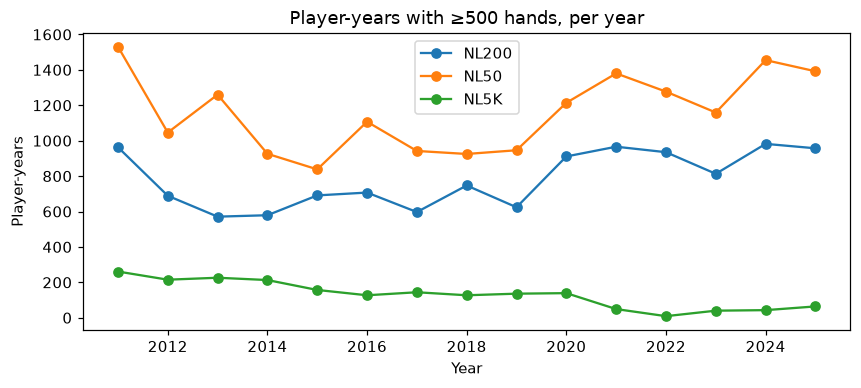

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for ds, g in py.groupby("dataset"):
    ax.plot(g.groupby("year").size(), marker="o", label=ds)
ax.set(title="Player-years with ≥500 hands, per year", xlabel="Year", ylabel="Player-years")
ax.legend()
plt.show()

## 2. Data quality checks

Before looking for unusual *players*, check for unusual *data*. Anything impossible here is a bug, not a cheater, and would pollute the detectors.

In [4]:
checks = {
    "c-bets > c-bet chances (c-bet % above 100)": py.cbets > py.cbet_opps,
    "PFR above VPIP (impossible)": py.pfr_pct > py.vpip_pct,
    "VPIP = 0 over 500+ hands": py.vpip_pct == 0,
}
pd.DataFrame(
    {"rows": {k: int(v.sum()) for k, v in checks.items()},
     "by dataset": {k: py.loc[v, "dataset"].value_counts().to_dict() for k, v in checks.items()}}
)

,rows,by dataset
c-bets > c-bet chances (c-bet % above 100),726,"{'NL50': 370, 'NL200': 334, 'NL5K': 22}"
PFR above VPIP (impossible),0,{}
VPIP = 0 over 500+ hands,15,"{'NL50': 10, 'NL200': 5}"


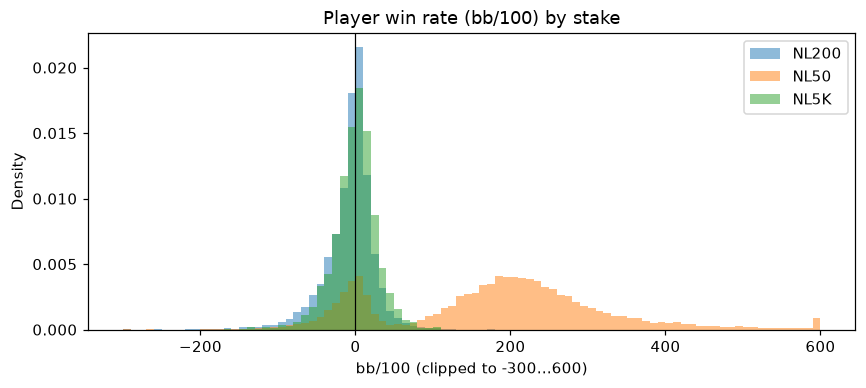

,median bb/100
dataset,
NL200,-2.005
NL50,191.035
NL5K,1.820


In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.linspace(-300, 600, 91)
for ds, g in py.groupby("dataset"):
    ax.hist(g.bb100.clip(-300, 600), bins=bins, alpha=0.5, label=ds, density=True)
ax.axvline(0, color="k", lw=0.8)
ax.set(title="Player win rate (bb/100) by stake", xlabel="bb/100 (clipped to -300…600)", ylabel="Density")
ax.legend()
plt.show()

py.groupby("dataset").bb100.median().rename("median bb/100").to_frame()

**What this shows:**

- **NL50 win rates are broken.** Poker is a zero-sum game minus rake, so the typical player should be slightly *negative*, as at NL200 and NL5K. At NL50 the median player wins far more than any real player could. `reports/metrics_bb100.csv` has the correct *population* NL50 win rate, so the bug is in the player-year export. It was most likely made before the NL50 parser fix (`7eb593a`) and needs re-running on the machine that has the Parquet data.
- **Some c-bet counts exceed the number of chances**, which points to a counting bug in the c-bet query.
- A handful of rows show VPIP = 0 over 500+ hands, which is almost certainly a parsing problem, not a real player.

For now, the rest of this notebook **drops NL50 bb/100, drops impossible c-bet rows and VPIP = 0 rows**, and works around the rest.

In [6]:
clean = py[~checks["c-bets > c-bet chances (c-bet % above 100)"] & ~checks["VPIP = 0 over 500+ hands"]].copy()
clean.loc[clean.dataset == "NL50", "bb100"] = np.nan
print(f"Kept {len(clean):,} of {len(py):,} player-years")

Kept 30,339 of 31,080 player-years


## 3. Features

Two problems to handle before any detector sees the data:

1. **Small samples are noisy.** A player with 500 hands can show a 50% 3-bet just by luck. We keep player-years with **≥ 2,000 hands**, so a stat this extreme is more likely to be real.
2. **The game changes over time and across stakes.** A 9% 3-bet was aggressive in 2011 but normal in 2025. If we compare raw numbers, the detector just learns "old vs new". So each stat is turned into a **z-score within its stake and year**: how many standard deviations a player is from the players around them. Stake-years with fewer than 30 such players (NL5K 2021–2025) are too thin for that and are dropped.

We also add **VPIP − PFR**, the "passive gap" (how often a player calls instead of raising).

In [7]:
MIN_HANDS = 2_000
STYLE = ["vpip_pct", "pfr_pct", "three_bet_pct", "fold_to_3bet_pct",
         "bb_fold_pct", "bb_three_bet_pct", "cbet_pct", "vpip_pfr_gap"]

df = clean[clean.hands >= MIN_HANDS].copy()
df["vpip_pfr_gap"] = df.vpip_pct - df.pfr_pct
df = df.dropna(subset=STYLE)

# z-scores need enough peers: drop stake-years with fewer than 30 player-years (late NL5K)
MIN_PEERS = 30
peers = df.groupby(["dataset", "year"]).player_name.transform("size")
print("Dropped thin stake-years:", df[peers < MIN_PEERS].groupby(["dataset", "year"]).size().to_dict())
df = df[peers >= MIN_PEERS].copy()

grp = df.groupby(["dataset", "year"])
for col in STYLE:
    df[f"z_{col}"] = (df[col] - grp[col].transform("mean")) / grp[col].transform("std")
Z = [f"z_{c}" for c in STYLE]

print(f"{len(df):,} player-years with ≥{MIN_HANDS:,} hands")
df.groupby("dataset").size().rename("player-years").to_frame()

Dropped thin stake-years: {('NL5K', 2021): 8, ('NL5K', 2023): 1, ('NL5K', 2024): 2, ('NL5K', 2025): 5}
12,030 player-years with ≥2,000 hands


,player-years
dataset,
NL200,4752
NL50,6518
NL5K,760


BB call % is left out on purpose: BB fold + call + 3-bet always add up to 100%, so the third one adds no new information.

## 4. Looking at the population

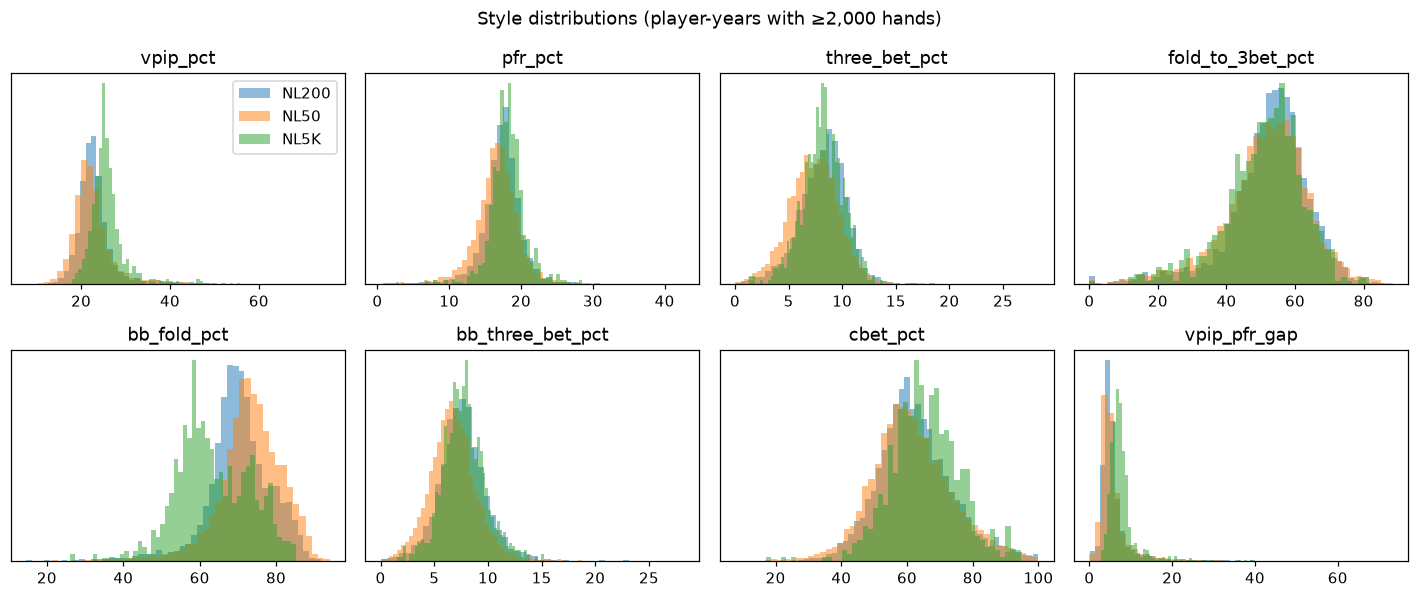

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, col in zip(axes.flat, STYLE):
    for ds, g in df.groupby("dataset"):
        ax.hist(g[col], bins=50, alpha=0.5, density=True, label=ds)
    ax.set_title(col)
    ax.set_yticks([])
axes[0, 0].legend()
fig.suptitle("Style distributions (player-years with ≥2,000 hands)")
fig.tight_layout()
plt.show()

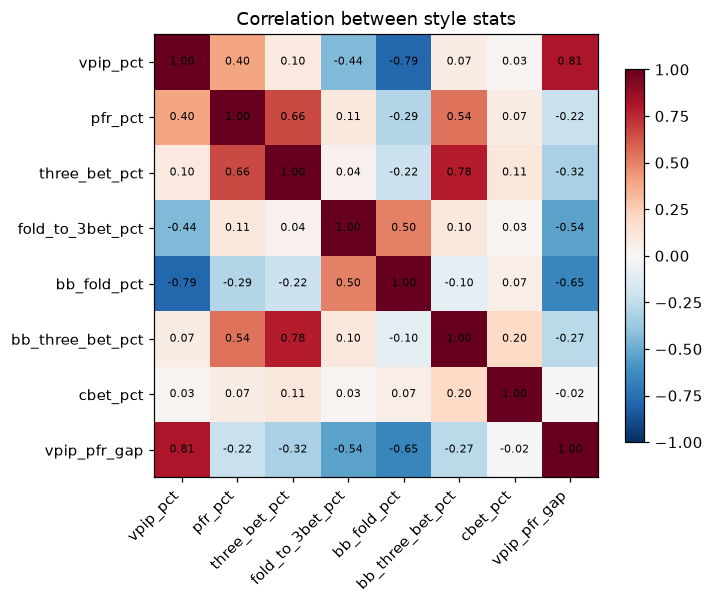

In [9]:
corr = df[STYLE].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(STYLE)), STYLE, rotation=45, ha="right")
ax.set_yticks(range(len(STYLE)), STYLE)
for i in range(len(STYLE)):
    for j in range(len(STYLE)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, shrink=0.8)
ax.set_title("Correlation between style stats")
plt.show()

Stats that move together (for example VPIP, PFR and 3-bet: aggressive players do all of them more) describe a shared **"how loose/aggressive" axis**. A player is unusual when their *combination* of stats breaks these normal relationships, not just when one stat is high. That is exactly what multivariate detectors look for.

**PCA** squeezes the 8 z-scores into 2 dimensions so we can draw the whole population as a map.

In [10]:
pca = PCA(n_components=2, random_state=RNG)
xy = pca.fit_transform(df[Z])
df["pc1"], df["pc2"] = xy[:, 0], xy[:, 1]
print("Variance explained by the two axes:", pca.explained_variance_ratio_.round(2))

loadings = pd.DataFrame(pca.components_.T, index=STYLE, columns=["PC1", "PC2"]).round(2)
loadings

Variance explained by the two axes: [0.36 0.32]


,PC1,PC2
vpip_pct,0.51,0.24
pfr_pct,-0.01,0.53
three_bet_pct,-0.16,0.55
fold_to_3bet_pct,-0.39,0.02
bb_fold_pct,-0.50,-0.20
bb_three_bet_pct,-0.13,0.53
cbet_pct,0.04,0.17
vpip_pfr_gap,0.55,-0.10


## 5. Unsupervised outlier detection

Two detectors with different ideas of "unusual":

- **Isolation Forest** builds random decision trees. Unusual points get separated (isolated) from everyone else in very few splits.
- **Local Outlier Factor (LOF)** compares each point's density with its neighbours'. A point sitting in a much emptier area than its neighbours is an outlier.

Both need a **contamination** setting, which is the share of points to call outliers. We use 1%. That is a choice, not a fact: nobody knows the real share of anomalous players.

In [11]:
CONTAMINATION = 0.01

iso = IsolationForest(n_estimators=300, contamination=CONTAMINATION, random_state=RNG)
df["iso_flag"] = iso.fit_predict(df[Z]) == -1
df["iso_score"] = -iso.score_samples(df[Z])  # higher = more anomalous

lof = LocalOutlierFactor(n_neighbors=35, contamination=CONTAMINATION)
df["lof_flag"] = lof.fit_predict(df[Z]) == -1
df["lof_score"] = -lof.negative_outlier_factor_

both = df.iso_flag & df.lof_flag
print(f"Isolation Forest flags {df.iso_flag.sum()}, LOF flags {df.lof_flag.sum()}, both agree on {both.sum()}")

Isolation Forest flags 121, LOF flags 121, both agree on 11


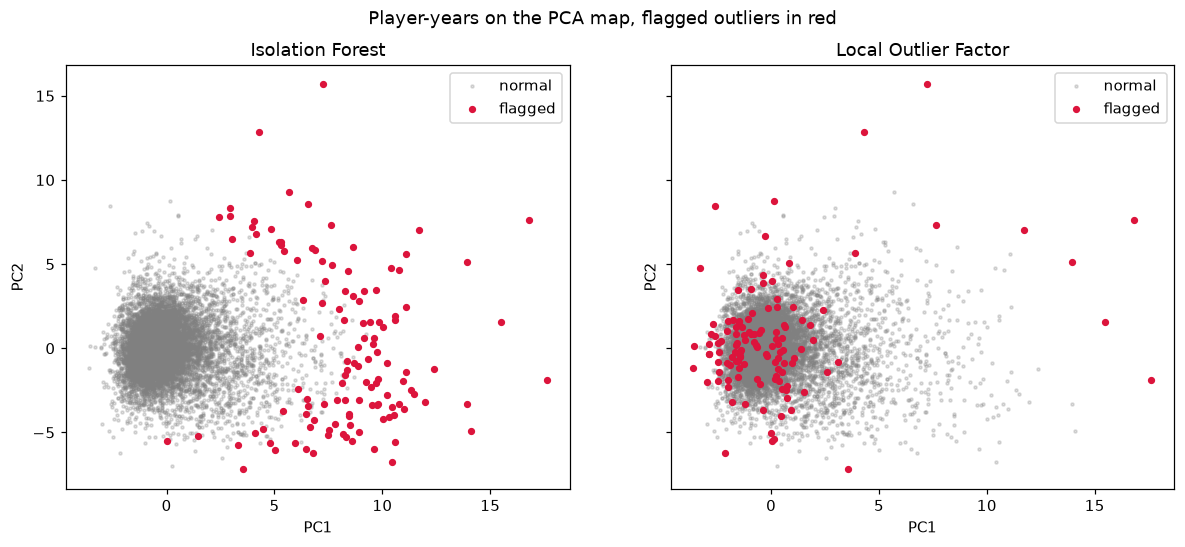

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, flag, name in [(axes[0], "iso_flag", "Isolation Forest"), (axes[1], "lof_flag", "Local Outlier Factor")]:
    normal = df[~df[flag]]
    out = df[df[flag]]
    ax.scatter(normal.pc1, normal.pc2, s=4, alpha=0.25, color="grey", label="normal")
    ax.scatter(out.pc1, out.pc2, s=14, color="crimson", label="flagged")
    ax.set(title=name, xlabel="PC1", ylabel="PC2")
    ax.legend()
fig.suptitle("Player-years on the PCA map, flagged outliers in red")
plt.show()

Isolation Forest mostly flags the **edges** of the cloud (extreme players). LOF can also flag points **inside** the cloud that sit in a sparse pocket. The two detectors overlap on only a small share of their flags, which is a useful lesson in itself: *what counts as an anomaly depends on the method*. Points flagged by both are the strongest candidates.

### What makes the flagged players unusual?

For each flagged player-year, list the stats furthest from their stake-and-year peers.

In [13]:
def top_reasons(row, n=3):
    z = row[Z].astype(float)
    top = z.abs().sort_values(ascending=False).head(n).index
    return ", ".join(f"{c[2:]} {z[c]:+.1f}σ" for c in top)

flagged = df[both].sort_values("iso_score", ascending=False).copy()
flagged["why"] = flagged.apply(top_reasons, axis=1)
flagged[["dataset", "year", "player_name", "hands", "vpip_pct", "pfr_pct", "three_bet_pct",
         "cbet_pct", "bb100", "why"]].head(20).round(1)

,dataset,year,player_name,hands,vpip_pct,pfr_pct,three_bet_pct,cbet_pct,bb100,why
9301,NL200,2023,luistd7,2227,65.2,42.7,22.8,80.1,-59.4,"bb_three_bet_pct +8.8σ, pfr_pct +8.3σ, vpip_pc..."
16788,NL50,2015,jonast92,2171,60.2,15.9,11.8,90.8,NaN,"vpip_pfr_gap +10.9σ, vpip_pct +9.3σ, bb_fold_p..."
24282,NL50,2022,Marsh DG,2529,69.0,27.6,12.2,44.8,NaN,"vpip_pct +9.1σ, vpip_pfr_gap +7.3σ, bb_fold_pc..."
7353,NL200,2021,CrazyGreek01,3254,49.8,30.6,28.3,79.8,-88.3,"bb_three_bet_pct +8.7σ, three_bet_pct +7.8σ, v..."
19726,NL50,2018,Waldemar M,2390,75.9,2.6,2.2,65.7,NaN,"vpip_pfr_gap +12.5σ, vpip_pct +9.9σ, bb_fold_p..."
10144,NL200,2024,Chamarindo,2705,52.5,17.9,18.2,72.0,-42.0,"bb_three_bet_pct +6.0σ, bb_fold_pct -5.3σ, vpi..."
2451,NL200,2014,MADDOG690,2279,65.2,37.2,8.5,76.3,-68.0,"vpip_pct +10.4σ, vpip_pfr_gap +10.1σ, bb_fold_..."
5647,NL200,2019,Powerpoint66,7374,20.2,1.1,0.6,96.2,-16.1,"pfr_pct -5.7σ, fold_to_3bet_pct -5.2σ, three_b..."
4454,NL200,2017,pok1718,2139,71.0,16.9,5.5,87.5,-59.8,"vpip_pfr_gap +10.6σ, vpip_pct +9.2σ, bb_fold_p..."
25584,NL50,2023,Strato11,2086,18.6,6.6,1.0,97.6,NaN,"pfr_pct -3.8σ, three_bet_pct -3.3σ, cbet_pct +..."


In [14]:
reason_counts = (
    flagged[Z].abs().idxmax(axis=1).str[2:].value_counts().rename("flagged player-years").to_frame()
)
reason_counts["share"] = (reason_counts.iloc[:, 0] / len(flagged)).round(2)
reason_counts

,flagged player-years,share
bb_three_bet_pct,4,0.36
vpip_pfr_gap,3,0.27
vpip_pct,2,0.18
pfr_pct,2,0.18


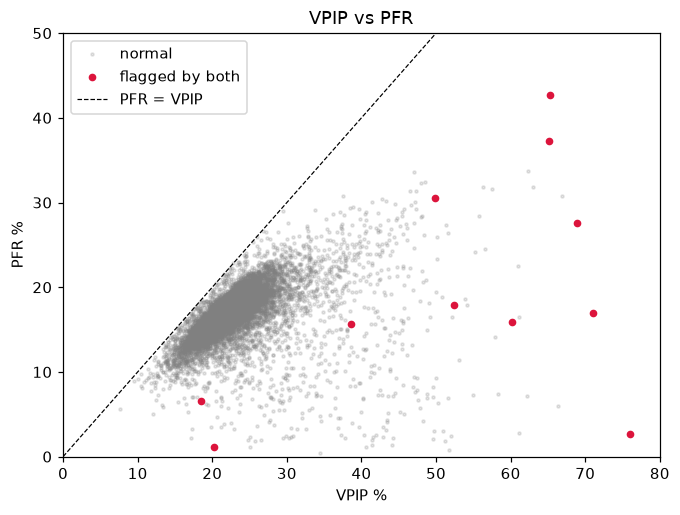

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df.vpip_pct, df.pfr_pct, s=4, alpha=0.2, color="grey", label="normal")
ax.scatter(flagged.vpip_pct, flagged.pfr_pct, s=16, color="crimson", label="flagged by both")
ax.plot([0, 100], [0, 100], "k--", lw=0.8, label="PFR = VPIP")
ax.set(xlim=(0, 80), ylim=(0, 50), xlabel="VPIP %", ylabel="PFR %", title="VPIP vs PFR")
ax.legend()
plt.show()

## Takeaways and next steps

- The player-year table is usable for style-based anomaly detection, after fixing or excluding the **NL50 win-rate** and **c-bet** bugs found in section 2. Both should be fixed at the source by re-running `compute_player_year_metrics.py` on the machine with the Parquet data.
- Comparing players **within their stake and year** stops the detector from just flagging "old" or "new" players.
- What the detectors find here are **unusual styles**: very passive players, extreme 3-bettors, players who never fold the big blind. Unusual is not the same as cheating. The players flagged here are mostly very loose or very passive and lose heavily where bb/100 is reliable, which is the profile of recreational players, not cheaters. A detector only becomes an integrity tool once its flags are checked against some form of ground truth.

**Next notebooks:**
- **02 · Style change over time:** compare each multi-year player with *their own* previous years (`metrics_player_stayers.csv`), to find sudden jumps in style or win rate (the RTA and account-sharing angle).
- **03 · Collusion candidates:** use the co-occurrence pairs to find players who sit together much more than their volume explains.
- **04 · Session behaviour:** needs the Parquet data. Rebuild sessions from per-hand timestamps and table names, and look at hours played, session length and multi-tabling.